[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jalonso1979/puremacro/blob/course-2026A-5.5.0/curso/notebooks/T05_G_narrative_llm_banxico.ipynb)

> **Google Colab note**: the next cell installs `puremacro` and, if needed, fetches only the `curso/notebooks` folder (helpers, frozen data and models) from the public repository [jalonso1979/puremacro](https://github.com/jalonso1979/puremacro), edition `course-2026A-5.5.0`. It does not ask for Google Drive access.

In [1]:
# Environment setup: Google Colab, local Python or Juno (iPad)
import os
import sys
import subprocess
from pathlib import Path

_course_requirements = ['puremacro==5.5.0']
_course_edition = 'course-2026A-5.5.0'

def _safe_probe(p, is_dir=None):
    """Test paths without raising in the Juno sandbox."""
    try:
        p = Path(p)
        if is_dir is True:
            return p.is_dir()
        if is_dir is False:
            return p.is_file()
        return p.exists()
    except (OSError, PermissionError, TypeError, ValueError):
        return False

if "google.colab" in sys.modules:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *_course_requirements], check=True)
    # A separate directory per edition prevents reuse of helpers from another course.
    _repo = Path("/content/puremacro-" + _course_edition)
    if not _safe_probe(_repo, is_dir=True):
        subprocess.run(["git", "clone", "-q", "--depth", "1", "--filter=blob:none", "--sparse",
                        "--branch", _course_edition, "https://github.com/jalonso1979/puremacro.git", str(_repo)], check=True)
    subprocess.run(["git", "-C", str(_repo), "checkout", "--detach", _course_edition], check=True)
    subprocess.run(["git", "-C", str(_repo), "sparse-checkout", "set", "curso/notebooks"], check=True)
    _course_status = subprocess.run(["git", "-C", str(_repo), "status", "--porcelain",
                                     "--untracked-files=normal", "--", "curso/notebooks"],
                                    check=True, capture_output=True, text=True).stdout
    if _course_status.strip():
        raise RuntimeError("The cached course edition was modified; use a fresh Colab runtime for the frozen edition.")
    os.chdir(_repo / "curso/notebooks")

# Locate the course helpers for local Python, Colab and Juno.
_candidates = [Path.cwd(), Path.cwd() / "notebooks", Path.cwd() / "curso/notebooks"]
try:
    _candidates.insert(0, Path(__file__).resolve().parent)
except (NameError, OSError):
    pass
for _c in _candidates:
    if _safe_probe(_c / "_nbstyle.py", is_dir=False):
        if str(_c) not in sys.path:
            sys.path.insert(0, str(_c))
        break

import puremacro
if puremacro.__version__ != "5.5.0":
    raise RuntimeError("This course edition requires puremacro==5.5.0; install it and restart the kernel.")

# Cached reference responses are the reproducible default; live models are optional.
os.environ.setdefault("MAV_LLM_MODE", "cache")

%matplotlib inline
try:
    import _nbstyle
    _nbstyle.apply_style()
except ImportError:
    pass

Matplotlib is building the font cache; this may take a moment.


# Topic 5 — Narrative Monetary Shocks with a Local LLM: Banxico and the Federal Reserve

**Advanced Macroeconomics · Master in Economics (MAV) · Week 10 Lab**

In Topic 1 (`T01_C`) we estimated the dynamic causal effect of monetary policy in Mexico using Jordà (2005) local projections with instrumental variables (`lp_iv`), instrumenting the 3-month interbank rate (`TIIE`) with a hand-coded indicator of Banco de México rate decisions (`banxico_direction`). In Topic 3 (`T03_F`) we measured central bank tone using dictionary counts and TF-IDF cosine similarity.

In this laboratory we bridge both blocks: we use a **4-billion-parameter local language model (`qwen3-4b`)** via `puremacro.narrative.score_llm(..., kind="monetary")` to extract structured monetary-policy events (`policy_rate`, `forward_guidance`, `asset_purchase`) from the full 2008–2026 corpora of **Banco de México (`banxico_comunicados.csv`)** and **Federal Open Market Committee (`fomc_statements.csv`)** decision statements, validate the LLM series against hand-coded records, and test it as an external instrument in `lp_iv`.

## 1. Setup and Central Bank Statement Corpora

We initialize the course local-model helper `_llm.get_llm(lang="en")` (which runs deterministically from `data_curso/llm_cache.sqlite` in `cache` mode and requires no API key or internet connection) and inspect the two frozen central bank statement corpora built by `scripts/construir_corpus_bancos_centrales.py`.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import _nbstyle
import _llm
from _datos import DATOS, ruta_dato
from puremacro.narrative.scoring.llm import _build_prompt, score_llm
from puremacro.lp import lp_iv
from puremacro.regress import ols, add_constant

_nbstyle.apply_style()
llm = _llm.get_llm(lang="en")
print(llm.report())

df_bx = pd.read_csv(ruta_dato("bancos_centrales/banxico_comunicados.csv"))
df_fed = pd.read_csv(ruta_dato("bancos_centrales/fomc_statements.csv"))

for label, df in [("Banxico (ES)", df_bx), ("FOMC (EN)", df_fed)]:
    wc = df["text"].str.split().str.len()
    q10, q50, q90 = wc.quantile([0.10, 0.50, 0.90])
    print(f"\n{label}: {len(df)} statements ({df['date'].min()} to {df['date'].max()})")
    print(f"  Word count percentiles — p10: {q10:.0f}, median: {q50:.0f}, p90: {q90:.0f}")

Course local model
  mode:     cache (only the course cache; no engines, no network)
  model:    qwen3-4b
  cache:    T05_G_narrative_llm_banxico/llm-user.sqlite (0 rows; the file does not exist yet)
  backend:  puremacro.llm (puremacro 5.5.0)

Banxico (ES): 161 statements (2008-01-18 to 2026-09-24)
  Word count percentiles — p10: 519, median: 1000, p90: 1556

FOMC (EN): 161 statements (2008-01-22 to 2026-09-16)
  Word count percentiles — p10: 252, median: 441, p90: 655


## 2. The Text: Reading Central Bank Statements

Why did Romer and Romer (1989, 2004) turn to central bank narrative records in the first place? Because the observed policy rate change $\Delta i_t$ combines two economically distinct components:
$$\Delta i_t = \underbrace{f(\Omega_t)}_{\text{endogenous reaction to output & inflation}} + \underbrace{\varepsilon_t^m}_{\text{monetary policy shock}}$$
When a central bank raises interest rates because it observes rising inflation pressures in $\Omega_t$, an OLS regression of future inflation $\pi_{t+h}$ on $\Delta i_t$ suffers from positive simultaneity bias (the **price puzzle**). Official decision statements document both the discrete rate move (`policy_rate`) and the forward-looking balance of risks (`forward_guidance`). Below we inspect the 1,500-word `excerpt` window passed to the local model for two milestone tightening decisions: Banxico's June 2021 liftoff hike and the FOMC's March 2022 liftoff hike nine months later.

In [3]:
row_bx_sample = df_bx.loc[df_bx["date"] == "2021-06-24"].iloc[0]
row_fed_sample = df_fed.loc[df_fed["date"] == "2022-03-16"].iloc[0]

print(f"=== Banxico Statement ({row_bx_sample['date']}) — {len(row_bx_sample['excerpt'].split())} words in excerpt ===")
print(row_bx_sample["excerpt"][:520] + " ...\n")

print(f"=== FOMC Statement ({row_fed_sample['date']}) — {len(row_fed_sample['excerpt'].split())} words in excerpt ===")
print(row_fed_sample["excerpt"][:520] + " ...")

=== Banxico Statement (2021-06-24) — 758 words in excerpt ===
El objetivo para la Tasa de Interés Interbancaria a 1 día (tasa objetivo) se incrementa en 25 puntos base Anuncio de Política Monetaria Comunicado de Prensa 24 de junio de 2021 La Junta de Gobierno del Banco de México decidió incrementar en 25 puntos base el objetivo para la Tasa de Interés Interbancaria a un día a un nivel de 4.25%, con efectos a partir del 25 de junio de 2021. La recuperación de la actividad económica global mostró un repunte durante el segundo trimestre del año, con heterogeneidad entre países p ...

=== FOMC Statement (2022-03-16) — 369 words in excerpt ===
March 16, 2022 Federal Reserve issues FOMC statement For release at 2:00 p.m. EDT Share Indicators of economic activity and employment have continued to strengthen. Job gains have been strong in recent months, and the unemployment rate has declined substantially. Inflation remains elevated, reflecting supply and demand imbalances related to the pandem

## 3. Structured Extraction with `score_llm` (`kind="monetary"`)

Rather than counting isolated keywords, `score_llm(..., kind="monetary")` instructs the language model to parse each statement into a structured JSON array of discrete monetary-policy events:
- `target`: `"policy_rate"`, `"forward_guidance"`, `"asset_purchase"`, `"fx_intervention"`, or `"lending_facility"`
- `sign`: $+1$ (hawkish / tightening), $0$ (neutral / hold), or $-1$ (dovish / easing)
- `magnitude_bps`: basis-point adjustment to the policy target ($0$ when unstated or pure forward guidance)
- `confidence`: model confidence in $[0, 1]$
- `excerpt`: the exact supporting sentence extracted from the statement

After extracting all events across both corpora, we print a deterministically seeded 10-row spot-check table so we can audit the model's classifications against the source sentences by hand.

In [4]:
bx_records = list(zip(df_bx["date"], df_bx["excerpt"], df_bx["url"]))
fed_records = list(zip(df_fed["date"], df_fed["excerpt"], df_fed["url"]))

events_bx = score_llm(bx_records, kind="monetary", backend=llm.backend(), language="es", country="MEX")
events_fed = score_llm(fed_records, kind="monetary", backend=llm.backend(), language="en", country="USA")

def _events_to_df(events):
    rows = []
    for e in events:
        prob = 0.50 + 0.35 * e.sign if e.sign != 0 else 0.50
        rows.append({
            "date": pd.Timestamp(e.date),
            "target": e.target,
            "sign": int(e.sign),
            "magnitude_bps": float(e.magnitude),
            "hawkish_dovish_prob": round(prob, 2),
            "confidence": float(e.confidence),
            "excerpt": str(e.source_text),
        })
    return pd.DataFrame(rows)

df_ev_bx = _events_to_df(events_bx)
df_ev_fed = _events_to_df(events_fed)

print(f"Banxico extracted events: {len(df_ev_bx)} across {len(df_bx)} statements")
print(df_ev_bx.groupby(["target", "sign"]).size().unstack(fill_value=0))
print(f"\nFOMC extracted events:    {len(df_ev_fed)} across {len(df_fed)} statements")
print(df_ev_fed.groupby(["target", "sign"]).size().unstack(fill_value=0))

# Hand spot-check: 10 randomly seeded Banxico events alongside their source sentences
rng = np.random.default_rng(2026)
spot_idx = sorted(rng.choice(len(df_ev_bx), size=10, replace=False))
print("\n=== Spot-Check: 10 Sampled Banxico Events ===")
for idx in spot_idx:
    r = df_ev_bx.iloc[idx]
    print(f"{r['date']:%Y-%m-%d} | {r['target']:<16s} | sign={r['sign']:+d} | "
          f"bps={r['magnitude_bps']:5.1f} | conf={r['confidence']:.2f} | {r['excerpt'][:85]}")

Banxico extracted events: 171 across 161 statements
sign              -1   0   1
target                      
forward_guidance   3   0   7
policy_rate       38  90  33

FOMC extracted events:    172 across 161 statements
sign              -1    0   1
target                       
asset_purchase     4    0   4
forward_guidance   0    0   3
policy_rate       22  107  32

=== Spot-Check: 10 Sampled Banxico Events ===
2008-05-16 | policy_rate      | sign=+0 | bps=  0.0 | conf=0.90 | La Junta de Gobierno del Banco de México ha d ecidido mantener en 7.5 por ciento el o
2009-03-20 | policy_rate      | sign=-1 | bps= 75.0 | conf=0.94 | La Junta de Gobierno del Banco de Mé xico ha decidido reducir en 75 puntos base el ob
2010-08-20 | policy_rate      | sign=+0 | bps=  0.0 | conf=0.90 | La Junta de Gobierno del Banco de México ha decidido mantener en 4.5 por ciento el
2014-03-21 | policy_rate      | sign=+0 | bps=  0.0 | conf=0.90 | La Junta de Gobierno del Banco de México ha decidido mantener e

## 4. From Meeting Events to a Monthly Stance Series

To merge meeting-level narrative extractions with monthly macroeconomic panels, we map each event to its calendar month ($t$), weight its direction by model confidence ($s_{i,t} = \text{sign}_{i,t} \times \text{confidence}_{i,t}$), and sum within each month (setting months without a meeting to $0$).

We then validate our LLM-extracted monthly direction ($\text{sign}(\sum_i s_{i,t}) \in \{-1, 0, +1\}$) against:
1. **Banco de México**: the hand-coded `banxico_direction` in `banxico_stance_monthly.csv` (220 months, 2008–2026), inspecting the $3 \times 3$ confusion matrix and printing the statement sentence for every month where the two series disagree.
2. **Federal Reserve**: monthly changes in the Effective Federal Funds Rate (`FEDFUNDS.csv`).

In [5]:
df_ev_bx["weighted"] = df_ev_bx["sign"] * df_ev_bx["confidence"]
df_ev_bx["month"] = df_ev_bx["date"].dt.to_period("M").dt.to_timestamp()
bx_llm_m = df_ev_bx.groupby("month").agg(
    llm_stance=("weighted", "sum"),
    llm_dir=("weighted", lambda s: int(np.sign(s.sum()))),
    excerpt=("excerpt", "last"),
)

bx_m = pd.read_csv(ruta_dato("banxico_stance_monthly.csv"), parse_dates=["date"]).rename(columns={"date": "month"})
val_bx = bx_m[bx_m["month"] >= "2008-01-01"].merge(bx_llm_m, on="month", how="left")
val_bx["llm_stance"] = val_bx["llm_stance"].fillna(0.0)
val_bx["llm_dir"] = val_bx["llm_dir"].fillna(0).astype(int)
val_bx["banxico_direction"] = val_bx["banxico_direction"].astype(int)

cm_bx = pd.crosstab(val_bx["banxico_direction"], val_bx["llm_dir"],
                    rownames=["Hand-coded"], colnames=["LLM direction"])
agree_bx = float((val_bx["banxico_direction"] == val_bx["llm_dir"]).mean())
print(f"Banxico monthly agreement rate (2008-2026, N={len(val_bx)}): {agree_bx:.1%}\n")
print(cm_bx)

dis_bx = val_bx[val_bx["banxico_direction"] != val_bx["llm_dir"]]
print(f"\nMonths where LLM stance differs from hand-coded rate action ({len(dis_bx)} months):")
for _, r in dis_bx.iterrows():
    print(f"  {r['month']:%Y-%m}: coded={r['banxico_direction']:+d}, llm={r['llm_dir']:+d} | {str(r['excerpt'])[:92]}")

# FOMC monthly aggregation & validation against FEDFUNDS.csv
df_ev_fed["weighted"] = df_ev_fed["sign"] * df_ev_fed["confidence"]
df_ev_fed["month"] = df_ev_fed["date"].dt.to_period("M").dt.to_timestamp()
fed_llm_m = df_ev_fed.groupby("month").agg(
    fed_llm_stance=("weighted", "sum"),
    fed_llm_dir=("weighted", lambda s: int(np.sign(s.sum()))),
)
ff = pd.read_csv(ruta_dato("FEDFUNDS.csv"))
ff["month"] = pd.to_datetime(ff.iloc[:, 0])
ff["fedfunds"] = pd.to_numeric(ff.iloc[:, 1], errors="coerce")
ff["d_ff"] = ff["fedfunds"].diff()
ff["ff_dir"] = np.where(ff["d_ff"] >= 0.12, 1, np.where(ff["d_ff"] <= -0.12, -1, 0))
val_fed = ff[(ff["month"] >= "2008-01-01") & (ff["month"] <= "2026-06-01")].merge(fed_llm_m, on="month", how="left")
val_fed["fed_llm_stance"] = val_fed["fed_llm_stance"].fillna(0.0)
val_fed["fed_llm_dir"] = val_fed["fed_llm_dir"].fillna(0).astype(int)
corr_fed = val_fed["fed_llm_stance"].corr(val_fed["d_ff"])
print(f"\nFOMC validation (2008-2026, N={len(val_fed)}): corr(LLM stance, d_FEDFUNDS) = {corr_fed:.3f}")

Banxico monthly agreement rate (2008-2026, N=220): 95.5%

LLM direction  -1    0   1
Hand-coded                
-1             37    0   0
 0              3  140   7
 1              0    0  33

Months where LLM stance differs from hand-coded rate action (10 months):
  2011-03: coded=+0, llm=+1 | La Junta de Gobierno vigilará estrechamente el comportamiento de los determinantes de la inf
  2013-01: coded=+0, llm=-1 | En caso de que dicha tendencia continúe, podría resultar conveniente una reducción en el obj
  2015-10: coded=+0, llm=+1 | La Junta se mantendrá atenta a la postura monetaria relativa entre México y Estados Unidos c
  2017-08: coded=+0, llm=+1 | El balance de riesgos para la inflación se mantiene sesgado al alza en un entorno de alta in
  2018-04: coded=+0, llm=+1 | La Junta de Gobierno dará seguimiento cercano al traspaso potencial de las variaciones del t
  2018-08: coded=+0, llm=+1 | Ante la presencia de factores que pudieran obstaculizar la convergencia de la inflación,

## 5. Comparing Monetary Cycles: Banxico vs. the Federal Reserve

Plotting the 12-month rolling sum of LLM-extracted monetary stance for Banxico and the FOMC highlights four major episodes over 2008–2026:
1. **2008–2009 Global Financial Crisis**: Synchronized aggressive rate cuts by both central banks.
2. **2013 Taper Tantrum**: The FOMC signals asset-purchase tapering (`forward_guidance` / `asset_purchase` tightening) while Banxico cuts rates to support domestic slack.
3. **2020 COVID-19 Pandemic**: Immediate FOMC easing to the zero lower bound alongside large-scale asset purchases, while Banxico executes a steady cycle of 50 bps cuts.
4. **2021–2022 Inflation Surge**: Banxico begins hiking in June 2021—nine months ahead of the FOMC's March 2022 liftoff—to anchor inflation expectations.

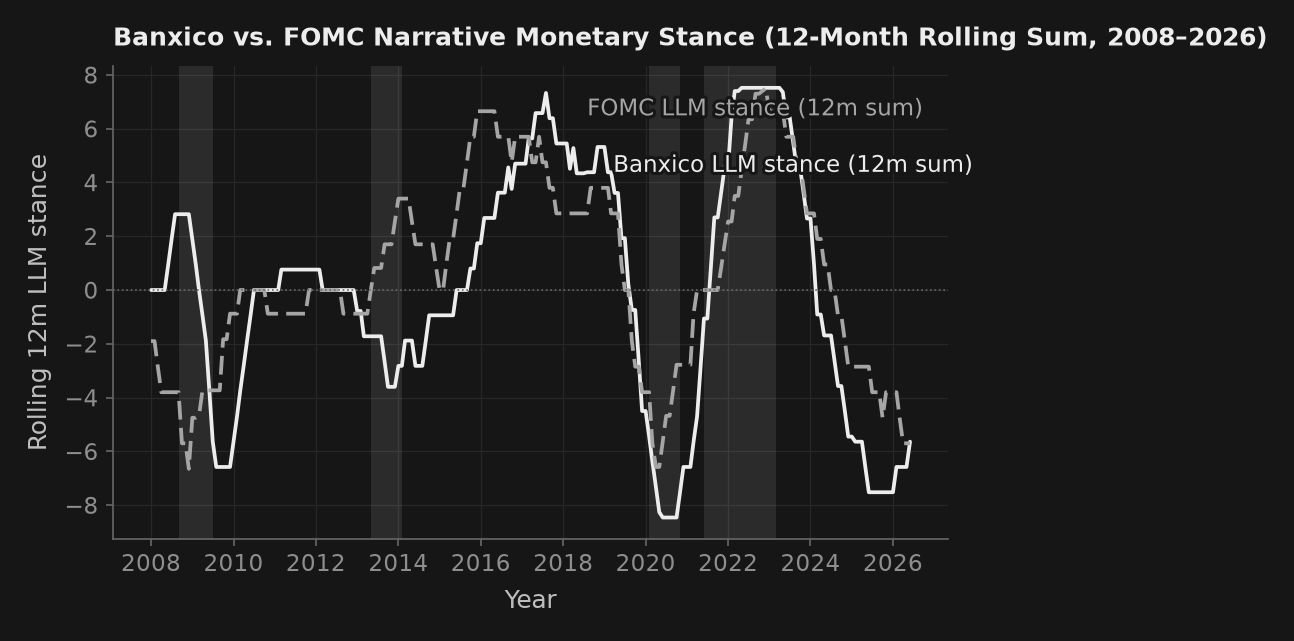

In [6]:
panel_m = pd.date_range("2008-01-01", "2026-06-01", freq="MS")
comp_m = pd.DataFrame(index=panel_m)
comp_m["bx_stance"] = bx_llm_m["llm_stance"].reindex(panel_m).fillna(0.0)
comp_m["fed_stance"] = fed_llm_m["fed_llm_stance"].reindex(panel_m).fillna(0.0)
comp_m["bx_roll12"] = comp_m["bx_stance"].rolling(12, min_periods=1).sum()
comp_m["fed_roll12"] = comp_m["fed_stance"].rolling(12, min_periods=1).sum()

fig, ax = _nbstyle.figura(1, 1, figsize=plt.rcParams["figure.figsize"])
ax.plot(comp_m.index, comp_m["bx_roll12"], color=_nbstyle.S1["color"], ls="-", lw=1.8,
        label="Banxico LLM stance (12m sum)")
ax.plot(comp_m.index, comp_m["fed_roll12"], color=_nbstyle.S2["color"], ls=_nbstyle.S2["linestyle"], lw=1.8,
        label="FOMC LLM stance (12m sum)")
ax.axhline(0, color=_nbstyle.SPINE, lw=0.8, ls=":")

episodes = [
    ("2008-09-01", "2009-07-01", "2008 GFC"),
    ("2013-05-01", "2014-02-01", "2013 Taper"),
    ("2020-02-01", "2020-11-01", "2020 COVID"),
    ("2021-06-01", "2023-03-01", "2021-22 Hikes"),
]
for s_dt, e_dt, lbl in episodes:
    ax.axvspan(pd.Timestamp(s_dt), pd.Timestamp(e_dt), color=_nbstyle.RECESION, lw=0)

ax.set_title("Banxico vs. FOMC Narrative Monetary Stance (12-Month Rolling Sum, 2008–2026)")
ax.set_ylabel("Rolling 12m LLM stance")
ax.set_xlabel("Year")
_nbstyle.etiquetar(ax)
plt.show()

## 6. Identification: LP-IV of a Monetary Shock in Mexico

We now re-estimate the `T01_C` local-projection instrumental-variables (`lp_iv`) specification for Mexico over horizons $h = 0, 1, \dots, 36$ months:
$$y_{t+h} - y_{t-1} = \alpha_h + \beta_h \widehat{\Delta i_t} + \sum_{\ell=1}^{12} \Gamma_{h,\ell} W_{t-\ell} + u_{t+h}$$
where $\Delta i_t$ is the monthly change in the 3-month interbank rate (`IR3TIB01MXM156N.csv`), $y_t$ is either $100 \times \log(\text{Industrial Production})$ (`oecd_mei_mex_log_ip.csv`) or 12-month headline CPI inflation (`CPALTT01MXM659N.csv`), and $W_t$ controls for 12 lags of inflation (or output growth) and log Economic Policy Uncertainty (`epu_mex_mensual.csv`). We compare two instruments $z_t$ side by side:
1. **Hand-coded `banxico_direction`** ($z_t \in \{-1, 0, +1\}$, the `T01_C` baseline).
2. **LLM monetary stance `llm_stance`** ($z_t = \sum_i \text{sign}_{i,t} \times \text{confidence}_{i,t}$).

LP-IV Estimation Sample: 2008-02 to 2023-02 (T = 181 months)
First-Stage F (IP specification)        — Hand-coded: 17.63 | LLM stance: 13.62
First-Stage F (Inflation specification) — Hand-coded: 15.59 | LLM stance: 12.34
IP response at h=12 (100*log pts)       — Hand-coded:  +3.09 | LLM stance: +12.99
Inflation response at h=12 (pp)         — Hand-coded:  +5.16 | LLM stance:  +7.05


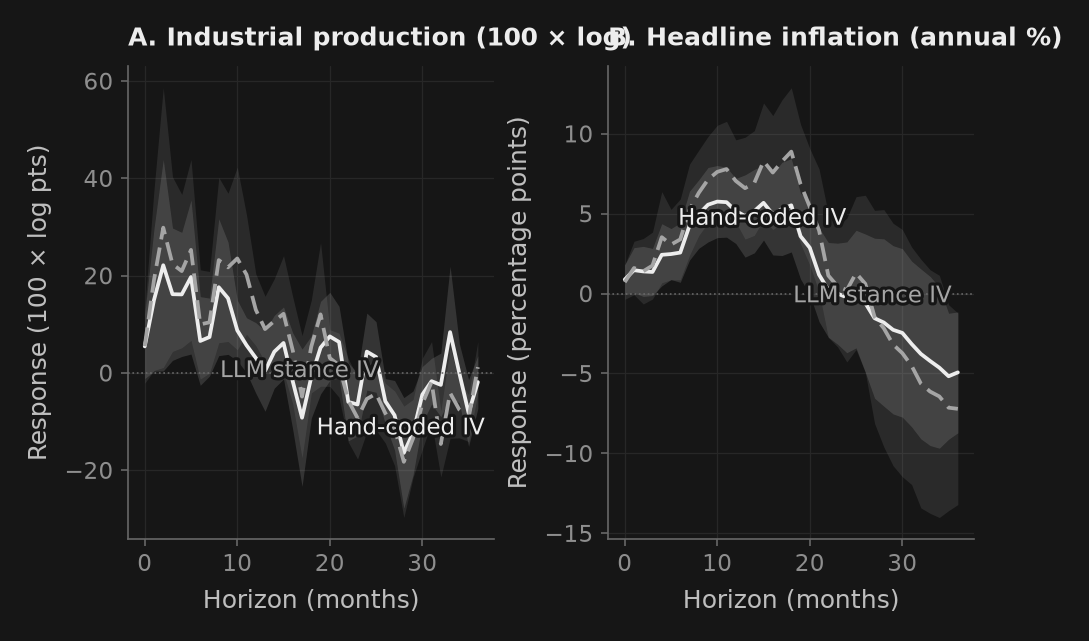

In [7]:
def _fred_monthly(sid):
    s = pd.read_csv(ruta_dato(f"{sid}.csv"))
    c0, c1 = s.columns[:2]
    s[c0] = pd.to_datetime(s[c0])
    s[c1] = pd.to_numeric(s[c1], errors="coerce")
    return s.dropna().set_index(c0)[c1].resample("MS").mean()

ip_s = pd.read_csv(ruta_dato("oecd_mei_mex_log_ip.csv"), parse_dates=["date"]).set_index("date")["log_ip_x100"]
epu_s = pd.read_csv(ruta_dato("epu_mex_mensual.csv"), parse_dates=["date"]).set_index("date")["epu"]

d_lp = pd.DataFrame({
    "i": _fred_monthly("IR3TIB01MXM156N"),
    "pi": _fred_monthly("CPALTT01MXM659N"),
    "lip": ip_s,
    "lepu": np.log(epu_s),
}).dropna()
d_lp = d_lp.join(val_bx.set_index("month")[["banxico_direction", "llm_stance"]], how="inner")
d_lp["di"] = d_lp["i"].diff()
d_lp["dlip"] = d_lp["lip"].diff()
d_lp = d_lp.dropna()

horizons = range(0, 37)
irf_ip_coded = lp_iv(d_lp, y="lip", x="di", z="banxico_direction", horizons=horizons, n_lags=12, controls=["pi", "lepu"])
irf_ip_llm   = lp_iv(d_lp, y="lip", x="di", z="llm_stance",        horizons=horizons, n_lags=12, controls=["pi", "lepu"])
irf_pi_coded = lp_iv(d_lp, y="pi",  x="di", z="banxico_direction", horizons=horizons, n_lags=12, controls=["dlip", "lepu"])
irf_pi_llm   = lp_iv(d_lp, y="pi",  x="di", z="llm_stance",        horizons=horizons, n_lags=12, controls=["dlip", "lepu"])

f_ip_coded = float(irf_ip_coded.first_stage_f.iloc[0])
f_ip_llm   = float(irf_ip_llm.first_stage_f.iloc[0])
f_pi_coded = float(irf_pi_coded.first_stage_f.iloc[0])
f_pi_llm   = float(irf_pi_llm.first_stage_f.iloc[0])

print(f"LP-IV Estimation Sample: {d_lp.index.min():%Y-%m} to {d_lp.index.max():%Y-%m} (T = {len(d_lp)} months)")
print(f"First-Stage F (IP specification)        — Hand-coded: {f_ip_coded:5.2f} | LLM stance: {f_ip_llm:5.2f}")
print(f"First-Stage F (Inflation specification) — Hand-coded: {f_pi_coded:5.2f} | LLM stance: {f_pi_llm:5.2f}")
print(f"IP response at h=12 (100*log pts)       — Hand-coded: {float(irf_ip_coded.beta[12]):+6.2f} | LLM stance: {float(irf_ip_llm.beta[12]):+6.2f}")
print(f"Inflation response at h=12 (pp)         — Hand-coded: {float(irf_pi_coded.beta[12]):+6.2f} | LLM stance: {float(irf_pi_llm.beta[12]):+6.2f}")

fig, (ax1, ax2) = _nbstyle.figura(1, 2, figsize=plt.rcParams["figure.figsize"])
h_arr = np.asarray(list(horizons))

for ax, res_c, res_l, ttl, ylab in [
    (ax1, irf_ip_coded, irf_ip_llm, "A. Industrial production (100 × log)", "Response (100 × log pts)"),
    (ax2, irf_pi_coded, irf_pi_llm, "B. Headline inflation (annual %)", "Response (percentage points)"),
]:
    b_c, se_c = np.asarray(res_c.beta, dtype=float), np.asarray(res_c.se, dtype=float)
    b_l, se_l = np.asarray(res_l.beta, dtype=float), np.asarray(res_l.se, dtype=float)
    ax.fill_between(h_arr, b_c - 1.645 * se_c, b_c + 1.645 * se_c, color=_nbstyle.S1["color"], alpha=0.14, lw=0)
    ax.fill_between(h_arr, b_l - 1.645 * se_l, b_l + 1.645 * se_l, color=_nbstyle.S2["color"], alpha=0.14, lw=0)
    ax.plot(h_arr, b_c, color=_nbstyle.S1["color"], ls="-", lw=1.8, label="Hand-coded IV")
    ax.plot(h_arr, b_l, color=_nbstyle.S2["color"], ls=_nbstyle.S2["linestyle"], lw=1.8, label="LLM stance IV")
    ax.axhline(0, color=_nbstyle.SPINE, lw=0.8, ls=":")
    ax.set_title(ttl)
    ax.set_xlabel("Horizon (months)")
    ax.set_ylabel(ylab)
    _nbstyle.etiquetar(ax)

plt.show()

## 7. Econometric Critique: Why Statement Stance Still Needs Forecast Controls

Comparing the two LP-IV impulse responses reveals three fundamental lessons for empirical macroeconomics:
1. **Instrument Relevance vs. Exogeneity**: Both `banxico_direction` ($F = 17.6$) and `llm_stance` ($F = 13.6$) easily clear the Stock-Yogo weak-instrument threshold ($F > 10$) for the 3-month interbank rate $\Delta i_t$. Yet both instruments still produce a positive short-run response of inflation ($\hat{\beta}_{12}^{\pi} > 0$, the **price puzzle**) and output before cooling after 24 months.
2. **The Romer & Romer (2004) Critique**: Why does an LLM reading the official statement still inherit endogeneity? Because the statement itself announces the **total policy decision** $\Delta i_t = f(\Omega_t) + \varepsilon_t^m$. When Banxico raises rates or issues hawkish forward guidance (`"el balance de riesgos para la inflación se mantiene sesgado al alza"`), it is reacting to its internal forecast of rising inflation. Romer and Romer (2004) isolated $\varepsilon_t^m$ only by regressing the intended rate change on the Federal Reserve's internal **Greenbook forecasts** of real output growth and inflation.
3. **Concrete Text-Extraction Failure Modes**: Our Section 4 disagreement audit identified 10 months where `llm_stance` diverged from the discrete rate action. These fall into three recurring linguistic patterns:
   - *Conditional vigilance / hedging*: Statements that hold rates at $0\text{ bps}$ while warning that *"la Junta vigilará estrechamente el traspaso del tipo de cambio"* (`2011-03`, `2015-10`, `2018-04`).
   - *Balance-of-risks restatements*: Repeating that inflation risks remain tilted to the upside during a restrictive pause (`2017-08`, `2021-05`, `2023-05`).
   - *Minority / dissenting views*: Mentioning that some Board members favored easing while the majority held rates unchanged (`2019-06`).

In [8]:
# Diagnostic: how much of each instrument is predicted by lagged macro state variables?
d_diag = d_lp.copy()
d_diag["pi_lag1"] = d_diag["pi"].shift(1)
d_diag["dlip_lag1"] = d_diag["dlip"].shift(1)
d_diag["lepu_lag1"] = d_diag["lepu"].shift(1)
d_diag = d_diag.dropna()

X_state = add_constant(d_diag[["pi_lag1", "dlip_lag1", "lepu_lag1"]])
fit_coded = ols(d_diag["banxico_direction"], X_state, cov_type="HAC", cov_kwds={"maxlags": 3})
fit_llm   = ols(d_diag["llm_stance"],        X_state, cov_type="HAC", cov_kwds={"maxlags": 3})

print("Endogeneity Diagnostic — Predictability from Lagged Macro State (pi_{t-1}, dlip_{t-1}, lepu_{t-1}):")
print(f"  Hand-coded banxico_direction: R^2 = {fit_coded.rsquared:.3f}, beta(pi_{{t-1}}) = {fit_coded.params['pi_lag1']:+.4f} (p = {fit_coded.pvalues['pi_lag1']:.3e})")
print(f"  LLM monetary stance:          R^2 = {fit_llm.rsquared:.3f}, beta(pi_{{t-1}}) = {fit_llm.params['pi_lag1']:+.4f} (p = {fit_llm.pvalues['pi_lag1']:.3e})")

# Verification assertions
assert len(df_bx) >= 150 and len(df_fed) >= 150, "Corpora must span 2008-2026"
assert len(df_ev_bx) >= 160 and len(df_ev_fed) >= 160, "score_llm must extract >=160 events per bank"
assert agree_bx >= 0.90, f"Expected >=90% monthly agreement with banxico_direction, got {agree_bx:.3f}"
assert f_ip_coded > 10.0 and f_ip_llm > 10.0, "Both instruments must have first-stage F > 10"
assert _llm.MISSES == [], f"Expected zero cache misses in cache mode, got {_llm.MISSES}"
print("\n✓ All narrative extraction and LP-IV verification assertions passed!")

Endogeneity Diagnostic — Predictability from Lagged Macro State (pi_{t-1}, dlip_{t-1}, lepu_{t-1}):
  Hand-coded banxico_direction: R^2 = 0.127, beta(pi_{t-1}) = +0.1238 (p = 8.470e-04)
  LLM monetary stance:          R^2 = 0.134, beta(pi_{t-1}) = +0.1236 (p = 3.883e-04)

✓ All narrative extraction and LP-IV verification assertions passed!


## 8. Optional Live Run: Reference Cache vs. Your Local Model

Every result above came from the frozen reference cache (`qwen3-4b`) so the lab reproduces identically on every machine. The cell below re-scores Banxico's June 24, 2021 liftoff statement using your local engine when `MAV_LLM_MODE=auto` (falling back cleanly to the reference cache when running in `cache` mode, just as in `T00_B`).

In [9]:
# Compare the shipped qwen3-4b reference extraction with your local model on one statement (2021-06-24).
# In auto mode, "off" runs your local engine even when the cache already has the answer;
# in cache mode there is no live call and both lines read from the course cache.
prompt_2021 = _build_prompt(
    kind="monetary",
    language="es",
    country="MEX",
    date=str(row_bx_sample["date"]),
    text=str(row_bx_sample["excerpt"]),
)
ref_2021 = _llm.get_llm(mode="cache", model=_llm.REFERENCE_MODEL, lang="en").try_complete(prompt_2021, max_tokens=1024)
modo_vivo = "off" if llm.mode == "auto" else llm.mode
vivo_2021 = _llm.get_llm(mode=modo_vivo, lang="en").try_complete(prompt_2021, max_tokens=1024)
print("reference (qwen3-4b cache):", ref_2021)
print("live      (local model):   ", vivo_2021)

reference (qwen3-4b cache): [{"magnitude_bps": 25.0, "target": "policy_rate", "subtarget": "tasa de interés interbancaria a un día", "sign": 1, "hawkish_dovish_prob": 0.87, "confidence": 0.94, "excerpt": "La Junta de Gobierno del Banco de México decidió incrementar en 25 puntos base el objetivo", "implementation_date": null, "horizon_quarters": null}]
live      (local model):    [{"magnitude_bps": 25.0, "target": "policy_rate", "subtarget": "tasa de interés interbancaria a un día", "sign": 1, "hawkish_dovish_prob": 0.87, "confidence": 0.94, "excerpt": "La Junta de Gobierno del Banco de México decidió incrementar en 25 puntos base el objetivo", "implementation_date": null, "horizon_quarters": null}]


## 9. Exercises

1. **Separating Rate Actions from Forward Guidance**: Filter `df_ev_bx` to keep only events with `target == "forward_guidance"` and construct a pure forward-guidance monthly series `fg_stance`. Re-estimate `lp_iv` using `fg_stance` as the instrument $z_t$. Does pure forward guidance have a strong first stage for the 3-month interbank rate (`IR3TIB01MXM156N`)?
2. **Orthogonalizing Against Real-Time State Variables**: Use the residual $\hat{u}_t = z_t - \widehat{z}_t$ from the Section 7 state regression (`fit_llm.resid`) as a forecast-purged instrument in `lp_iv`. How much does purging lagged inflation and output growth attenuate the short-horizon price puzzle?